<a href="https://colab.research.google.com/github/pedroUDF/ciencia_dados_maquina/blob/main/Projeto_DataScience/notebooks/modelagem_avaliacao_fase4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Estratégia da Fase 4
Algoritmos Selecionados:
* LogisticRegression: Modelo linear interpretável que serve como baseline
estatística.
* RandomForestClassifier: Ensemble de árvores de decisão em paralelo, robusto contra ruídos e relações não-lineares.
* HistGradientBoostingClassifier ou LightGBM / XGBoost: boosting, estado da arte para dados tabulares.

Tratamento do Desbalanceamento (~31% abstentes vs. ~69% presentes):
Uso do class_weight="balanced" nos modelos para penalizar erros na classe minoritária (abstentes) e maximizar o Recall (captura de potenciais desistentes), alinhado à meta técnica (ROC-AUC >= 0.75 e Recall >= 70%).

Comparação nos Dois Cenários da Fase 3:
Dataset A (Série Histórica 2023–2025): Treino em 2023–2024  Teste Out-of-Time em 2025. Avalia o poder preditivo apenas com dados escolares/estruturais.
Dataset B (Perfil Socioeconômico Completo 2023): Treino  Teste. Mensura o ganho real de performance ao adicionar renda (Q006), escolaridade dos pais e trajetória escolar.



FASE 4: MODELAGEM PREDITIVA

Reconstruindo matrizes da Fase 3 no GitHub...
Matrizes reconstruídas com sucesso!

=== TABELA COMPARATIVA DE PERFORMANCE DOS MODELOS (FASE 4) ===
                        Cenário                         Modelo  ROC-AUC  Recall (%)  Precision (%)  F1-Score  Acurácia (%)
    Dataset A (Série 2023-2025) Regressão Logística (Baseline)   0.6522       85.73          38.66    0.5329         52.47
    Dataset A (Série 2023-2025)                  Random Forest   0.6521       85.69          38.66    0.5328         52.48
    Dataset A (Série 2023-2025)     Gradient Boosting (HistGB)   0.6522       85.70          38.67    0.5329         52.49
Dataset B (Socioeconômico 2023) Regressão Logística (Baseline)   0.7137       66.95          46.46    0.5486         65.83
Dataset B (Socioeconômico 2023)                  Random Forest   0.7195       70.81          45.80    0.5563         64.97
Dataset B (Socioeconômico 2023)     Gradient Boosting (HistGB)   0.7205       69.59    

/tmp/ipykernel_644/1297270869.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, ax=axes[2], palette="viridis")


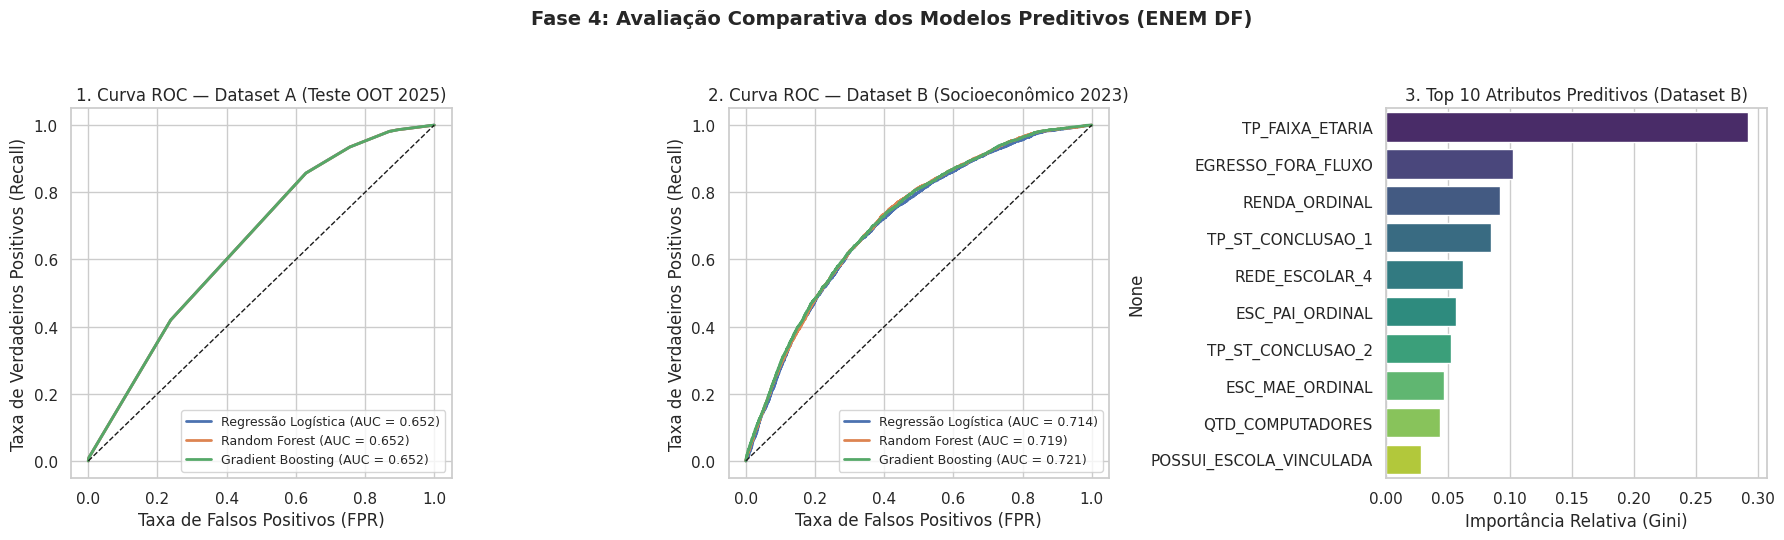

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score, f1_score,
    accuracy_score, roc_curve, confusion_matrix
)
import os

print("FASE 4: MODELAGEM PREDITIVA\n")

if os.path.exists("dados_modelagem/train_serie_A.parquet"):
    train_A = pd.read_parquet("dados_modelagem/train_serie_A.parquet")
    test_A = pd.read_parquet("dados_modelagem/test_serie_A.parquet")
    train_B = pd.read_parquet("dados_modelagem/train_socio_B.parquet")
    test_B = pd.read_parquet("dados_modelagem/test_socio_B.parquet")
    print("[OK] Matrizes carregadas de 'dados_modelagem/'.")
else:
    print("Reconstruindo matrizes da Fase 3 no GitHub...")
    base_url = "https://raw.githubusercontent.com/pedroUDF/ciencia_dados_maquina/main/Projeto_DataScience/data/processed"
    df_2023 = pd.read_parquet(f"{base_url}/2023_completo_df.parquet")
    df_2024_res = pd.read_parquet(f"{base_url}/2024_resultados_df.parquet")
    df_2025_res = pd.read_parquet(f"{base_url}/2025_resultados_df.parquet")

    def prep_est(df, ano):
        d = df[~((df["TP_PRESENCA_CH"] == 2) | (df["TP_PRESENCA_MT"] == 2))].copy()
        d["ANO"] = ano
        d["ABSTENCAO"] = ((d["TP_PRESENCA_CH"] == 0) | (d["TP_PRESENCA_MT"] == 0)).astype(int)
        d["POSSUI_ESCOLA_VINCULADA"] = d["TP_DEPENDENCIA_ADM_ESC"].notna().astype(int)
        d["ESTUDA_FORA_DF"] = (d["SG_UF_ESC"].notna() & (d["SG_UF_ESC"] != "DF")).astype(int)
        d["REDE_ESCOLAR"] = d["TP_DEPENDENCIA_ADM_ESC"].fillna(0).astype(int)
        d["LOCALIZACAO_ESC"] = d["TP_LOCALIZACAO_ESC"].fillna(0).astype(int)
        d["SIT_FUNC_ESC"] = d["TP_SIT_FUNC_ESC"].fillna(0).astype(int)
        d["UF_ESCOLA_CAT"] = d["SG_UF_ESC"].fillna("SEM_VINCULO").apply(
            lambda x: x if x in ["DF", "GO", "SEM_VINCULO"] else "OUTRA_UF"
        )
        d["TP_LINGUA"] = d["TP_LINGUA"].astype(int)
        cols = ["ANO", "POSSUI_ESCOLA_VINCULADA", "ESTUDA_FORA_DF", "REDE_ESCOLAR",
                "LOCALIZACAO_ESC", "SIT_FUNC_ESC", "UF_ESCOLA_CAT", "TP_LINGUA", "ABSTENCAO"]
        return d[cols]

    df_st = pd.concat([prep_est(df_2023, 2023), prep_est(df_2024_res, 2024), prep_est(df_2025_res, 2025)], ignore_index=True)
    df_st_enc = pd.get_dummies(df_st, columns=["REDE_ESCOLAR", "LOCALIZACAO_ESC", "SIT_FUNC_ESC", "UF_ESCOLA_CAT"], dtype=int)
    train_A = df_st_enc[df_st_enc["ANO"].isin([2023, 2024])].drop(columns=["ANO"])
    test_A = df_st_enc[df_st_enc["ANO"] == 2025].drop(columns=["ANO"])

    d23 = df_2023[~((df_2023["TP_PRESENCA_CH"] == 2) | (df_2023["TP_PRESENCA_MT"] == 2))].copy()
    d23["ABSTENCAO"] = ((d23["TP_PRESENCA_CH"] == 0) | (d23["TP_PRESENCA_MT"] == 0)).astype(int)
    d23["POSSUI_ESCOLA_VINCULADA"] = d23["TP_DEPENDENCIA_ADM_ESC"].notna().astype(int)
    d23["ESTUDA_FORA_DF"] = (d23["SG_UF_ESC"].notna() & (d23["SG_UF_ESC"] != "DF")).astype(int)
    d23["REDE_ESCOLAR"] = d23["TP_DEPENDENCIA_ADM_ESC"].fillna(0).astype(int)
    d23["EGRESSO_FORA_FLUXO"] = d23["TP_ST_CONCLUSAO"].isin([1, 4]).astype(int)
    mapa_renda = {l: i for i, l in enumerate(list("ABCDEFGHIJKLMNOPQ"))}
    mapa_esc = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6, "H": -1}
    mapa_bens = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
    d23["RENDA_ORDINAL"] = d23["Q006"].map(mapa_renda)
    d23["ESC_PAI_ORDINAL"] = d23["Q001"].map(mapa_esc)
    d23["ESC_MAE_ORDINAL"] = d23["Q002"].map(mapa_esc)
    d23["QTD_COMPUTADORES"] = d23["Q024"].map(mapa_bens)
    d23["ACESSO_INTERNET"] = (d23["Q025"] == "B").astype(int)
    d23["SEXO_MASC"] = (d23["TP_SEXO"] == "M").astype(int)
    cols_B = ["TP_FAIXA_ETARIA", "SEXO_MASC", "TP_ESTADO_CIVIL", "TP_COR_RACA", "TP_ST_CONCLUSAO",
              "IN_TREINEIRO", "POSSUI_ESCOLA_VINCULADA", "ESTUDA_FORA_DF", "EGRESSO_FORA_FLUXO",
              "REDE_ESCOLAR", "TP_LINGUA", "RENDA_ORDINAL", "ESC_PAI_ORDINAL", "ESC_MAE_ORDINAL",
              "QTD_COMPUTADORES", "ACESSO_INTERNET", "ABSTENCAO"]
    df_b_enc = pd.get_dummies(d23[cols_B], columns=["TP_ESTADO_CIVIL", "TP_COR_RACA", "TP_ST_CONCLUSAO", "REDE_ESCOLAR"], dtype=int)
    train_B, test_B = train_test_split(df_b_enc, test_size=0.20, random_state=42, stratify=df_b_enc["ABSTENCAO"])
    print("Matrizes reconstruídas com sucesso!")

# 2. DEFINIÇÃO DOS MODELOS CANDIDATOS
def obter_modelos():
    return {
        "Regressão Logística (Baseline)": make_pipeline(
            StandardScaler(),
            LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=10, min_samples_leaf=20,
            class_weight="balanced", n_jobs=-1, random_state=42
        ),
        "Gradient Boosting (HistGB)": HistGradientBoostingClassifier(
            max_iter=200, max_depth=6, learning_rate=0.05,
            class_weight="balanced", random_state=42
        )
    }

# 3. TREINAMENTO E AVALIAÇÃO NOS DOIS CENÁRIOS
def avaliar_cenario(nome_cenario, df_train, df_test):
    X_train = df_train.drop(columns=["ABSTENCAO"])
    y_train = df_train["ABSTENCAO"]
    X_test = df_test.drop(columns=["ABSTENCAO"])
    y_test = df_test["ABSTENCAO"]

    resultados = []
    curvas_roc = {}
    modelos_treinados = {}

    for nome_modelo, modelo in obter_modelos().items():
        modelo.fit(X_train, y_train)
        y_prob = modelo.predict_proba(X_test)[:, 1]
        y_pred = (y_prob >= 0.50).astype(int)

        auc = roc_auc_score(y_test, y_prob)
        rec = recall_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        acc = accuracy_score(y_test, y_pred)

        resultados.append({
            "Cenário": nome_cenario,
            "Modelo": nome_modelo,
            "ROC-AUC": round(auc, 4),
            "Recall (%)": round(rec * 100, 2),
            "Precision (%)": round(prec * 100, 2),
            "F1-Score": round(f1, 4),
            "Acurácia (%)": round(acc * 100, 2)
        })
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        curvas_roc[nome_modelo] = (fpr, tpr, auc)
        modelos_treinados[nome_modelo] = (modelo, y_test, y_prob, y_pred)

    return pd.DataFrame(resultados), curvas_roc, modelos_treinados, X_train.columns

res_A, roc_A, mods_A, cols_A = avaliar_cenario("Dataset A (Série 2023-2025)", train_A, test_A)
res_B, roc_B, mods_B, cols_B = avaliar_cenario("Dataset B (Socioeconômico 2023)", train_B, test_B)

df_comparativo = pd.concat([res_A, res_B], ignore_index=True)
print("\n=== TABELA COMPARATIVA DE PERFORMANCE DOS MODELOS (FASE 4) ===")
print(df_comparativo.to_string(index=False))

# 4. VISUALIZAÇÃO: CURVAS ROC + IMPORTÂNCIA DAS VARIÁVEIS (FEATURE IMPORTANCE)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle("Fase 4: Avaliação Comparativa dos Modelos Preditivos (ENEM DF)", fontsize=14, fontweight="bold")

# Plot 1: Curvas ROC Dataset A
for nome, (fpr, tpr, auc) in roc_A.items():
    axes[0].plot(fpr, tpr, lw=2, label=f"{nome.split(' (')[0]} (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("1. Curva ROC — Dataset A (Teste OOT 2025)")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend(loc="lower right", fontsize=9)

# Plot 2: Curvas ROC Dataset B
for nome, (fpr, tpr, auc) in roc_B.items():
    axes[1].plot(fpr, tpr, lw=2, label=f"{nome.split(' (')[0]} (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("2. Curva ROC — Dataset B (Socioeconômico 2023)")
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[1].legend(loc="lower right", fontsize=9)

# Plot 3: Top 10 Features mais importantes (Random Forest no Dataset B)
rf_B = mods_B["Random Forest"][0]
importancias = pd.Series(rf_B.feature_importances_, index=cols_B).sort_values(ascending=False).head(10)
sns.barplot(x=importancias.values, y=importancias.index, ax=axes[2], palette="viridis")
axes[2].set_title("3. Top 10 Atributos Preditivos (Dataset B)")
axes[2].set_xlabel("Importância Relativa (Gini)")

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()